# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Fajar Nurhidayat
- **Email:** fajarnurhidayat100@gmail.com  
- **ID Dicoding:** fajarnurhd

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari libur sepanjang tahun 2011–2012, serta pada jam berapa volume penyewaan tertinggi terjadi sebagai bahan pertimbangan penjadwalan redistribusi armada?
- **Pertanyaan 2:** Berapa persentase perbedaan rata-rata penyewaan sepeda per jam antara kondisi cuaca cerah dan cuaca buruk pada pengguna casual serta registered selama tahun 2011–2012, sebagai bahan pertimbangan strategi operasional saat perubahan cuaca?
- **Pertanyaan 3:** Bagaimana persentase peningkatan rata-rata peminjaman sepeda harian antar musim dari tahun 2011 ke 2012, dan kapan waktu paling low-risk untuk melakukan perbaikan armada massal?

#### Menyiapkan semua library yang dibutuhkan

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Data Wrangling
#### Gathering Data

In [37]:
day_df = pd.read_csv("./data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [38]:
hour_df = pd.read_csv("./data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Assessing Data
#### Menilai tabel day_df

In [39]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [40]:
day_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [41]:
print("Jumlah duplikasi: ", day_df.duplicated().sum())

Jumlah duplikasi:  0


In [42]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


#### Menilai tabel hour_df

In [43]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [44]:
hour_df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [45]:
print("Jumlah duplikasi: ", hour_df.duplicated().sum())

Jumlah duplikasi:  0


In [46]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


Insight:
- Tidak ditemukan duplikasi data di kedua dataset
- Tidak ditemukan missing values di kedua dataset
- Data bersih dan tidak perlu cleaning data

### Exploratory Data Analysis (EDA)

In [47]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [48]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


Insight:
- Untuk variabel season, yr, mnth, holiday, hr, weekday, workingday, weathersit masih bernilai integer, padahal merupakan tipe data kategorikal. Maka harus diubah ke tipe data kategorikal.
- Untuk variabel dteday di kedua datase masih bertipe data integer. Harus diubah dulu ke tipe data datetime.

In [49]:
day_df_cat = ['season','yr','mnth','holiday','weekday','workingday','weathersit']
for col in day_df_cat:
    day_df[col] = day_df[col].astype('category')

hour_df_cat = ['season','yr','mnth','hr','holiday','weekday','workingday','weathersit']
for col in hour_df_cat:
    hour_df[col] = hour_df[col].astype('category')

day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

In [50]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    category      
 3   yr          731 non-null    category      
 4   mnth        731 non-null    category      
 5   holiday     731 non-null    category      
 6   weekday     731 non-null    category      
 7   workingday  731 non-null    category      
 8   weathersit  731 non-null    category      
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: category(7), datetime64

In [51]:
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  category      
 3   yr          17379 non-null  category      
 4   mnth        17379 non-null  category      
 5   hr          17379 non-null  category      
 6   holiday     17379 non-null  category      
 7   weekday     17379 non-null  category      
 8   workingday  17379 non-null  category      
 9   weathersit  17379 non-null  category      
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

Insight:
- Untuk variabel season, yr, mnth, holiday, hr, weekday, workingday, weathersit sudah berubah menjadi tipe data kategorikal
- Untuk variabel dteday di kedua dataset sudah berubah menjadi tipe data datetime.

#### Analisis Univariat

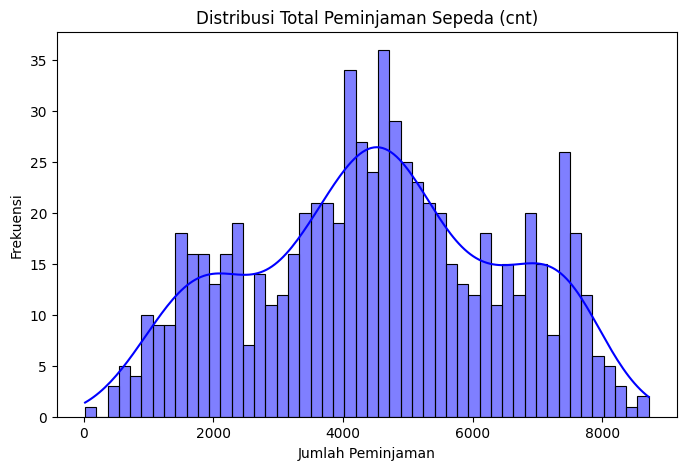

In [52]:
# Histogram Distribusi Target
plt.figure(figsize = (8,5))
sns.histplot(day_df['cnt'], bins=50, kde=True, color='blue')
plt.title('Distribusi Total Peminjaman Sepeda (cnt)')
plt.xlabel('Jumlah Peminjaman')
plt.ylabel('Frekuensi')
plt.show()

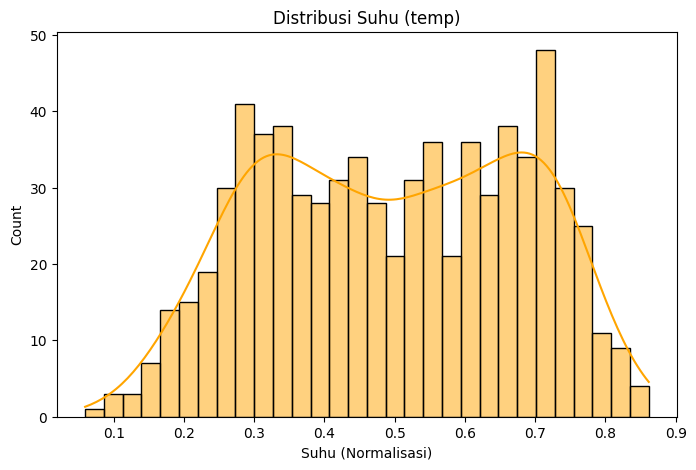

In [53]:
# Histogram Distribusi Variabel Cuaca (Suhu)
plt.figure(figsize=(8, 5))
sns.histplot(day_df['temp'], bins=30, kde=True, color='orange')
plt.title('Distribusi Suhu (temp)')
plt.xlabel('Suhu (Normalisasi)')
plt.show()

#### Analisis Bivariat

C:\Users\fajar\AppData\Local\Temp\ipykernel_15112\3412277467.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='season', y='cnt', data=day_df, palette='Set2')


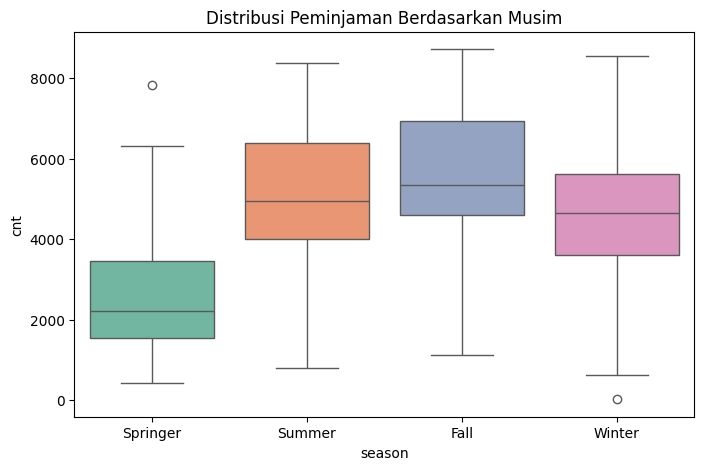

In [54]:
# Boxplot Musim vs Jumlah Peminjaman
plt.figure(figsize=(8, 5))
sns.boxplot(x='season', y='cnt', data=day_df, palette='Set2')
plt.title('Distribusi Peminjaman Berdasarkan Musim')
plt.xticks(ticks=[0, 1, 2, 3], labels=['Springer', 'Summer', 'Fall', 'Winter'])
plt.show()

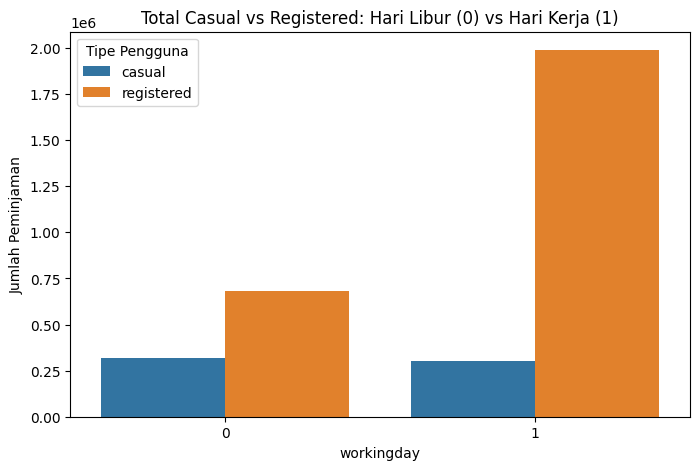

In [55]:
# Pola Penggunaan Casual vs Registered
df_melt = pd.melt(day_df, id_vars=['workingday'], 
                  value_vars=['casual', 'registered'], 
                  var_name='Tipe Pengguna', 
                  value_name='Jumlah Peminjaman')

plt.figure(figsize=(8, 5))
sns.barplot(x='workingday', 
            y='Jumlah Peminjaman', 
            hue='Tipe Pengguna', 
            data=df_melt, 
            estimator=sum, 
            errorbar=None)
plt.title('Total Casual vs Registered: Hari Libur (0) vs Hari Kerja (1)')
plt.show()

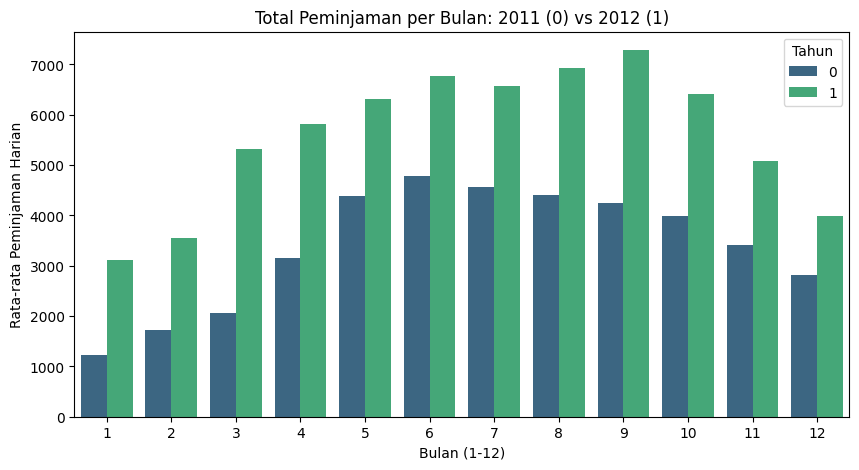

In [56]:
# Tren Peminjaman Bulanan (Berdasarkan Tahun)
plt.figure(figsize=(10, 5))
sns.barplot(x='mnth', y='cnt', hue='yr', data=day_df, palette='viridis', errorbar=None)
plt.title('Total Peminjaman per Bulan: 2011 (0) vs 2012 (1)')
plt.xlabel('Bulan (1-12)')
plt.ylabel('Rata-rata Peminjaman Harian')
plt.legend(title='Tahun')
plt.show()

C:\Users\fajar\AppData\Local\Temp\ipykernel_15112\2887903778.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='weekday', y='cnt', data=day_df, palette='pastel')


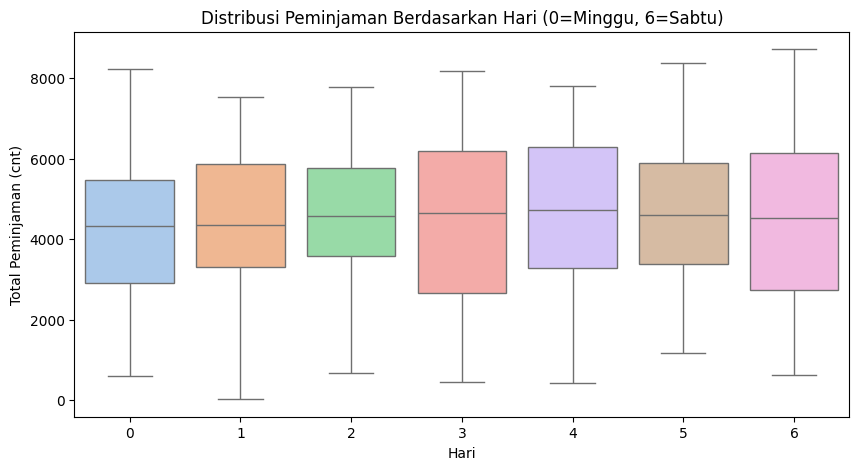

In [57]:
# Peminjaman Berdasarkan Hari dalam Seminggu
plt.figure(figsize=(10, 5))
sns.boxplot(x='weekday', y='cnt', data=day_df, palette='pastel')
plt.title('Distribusi Peminjaman Berdasarkan Hari (0=Minggu, 6=Sabtu)')
plt.xlabel('Hari')
plt.ylabel('Total Peminjaman (cnt)')
plt.show()

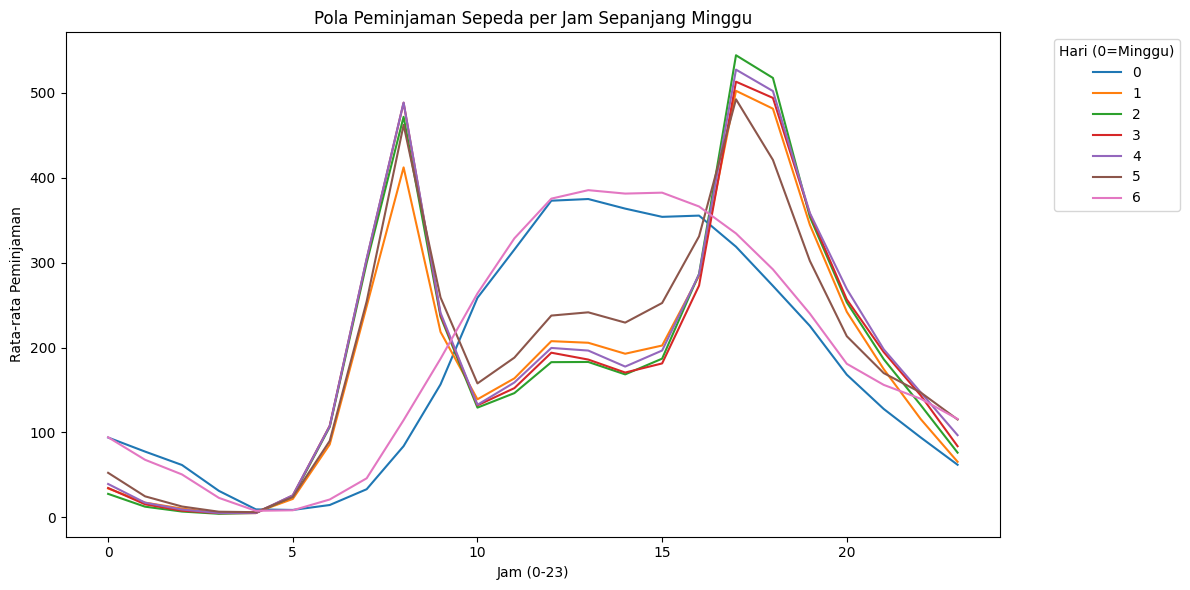

In [58]:
# Pola Peminjaman per Jam Berdasarkan Hari 
plt.figure(figsize=(12, 6))
sns.lineplot(x='hr', y='cnt', hue='weekday', data=hour_df, palette='tab10', errorbar=None)
plt.title('Pola Peminjaman Sepeda per Jam Sepanjang Minggu')
plt.xlabel('Jam (0-23)')
plt.ylabel('Rata-rata Peminjaman')
plt.legend(title='Hari (0=Minggu)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

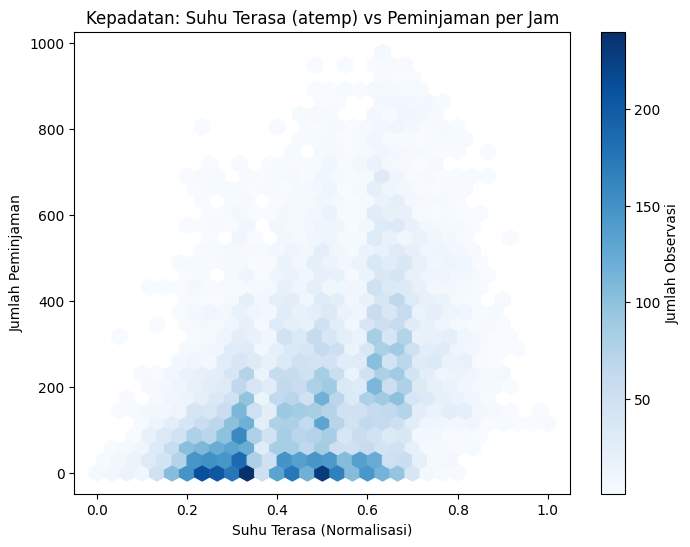

In [59]:
# Hubungan Suhu per Jam (atemp) vs Peminjaman
plt.figure(figsize=(8, 6))
plt.hexbin(hour_df['atemp'], hour_df['cnt'], gridsize=30, cmap='Blues', mincnt=1)
plt.colorbar(label='Jumlah Observasi')
plt.title('Kepadatan: Suhu Terasa (atemp) vs Peminjaman per Jam')
plt.xlabel('Suhu Terasa (Normalisasi)')
plt.ylabel('Jumlah Peminjaman')
plt.show()

#### Analisis Multivariat

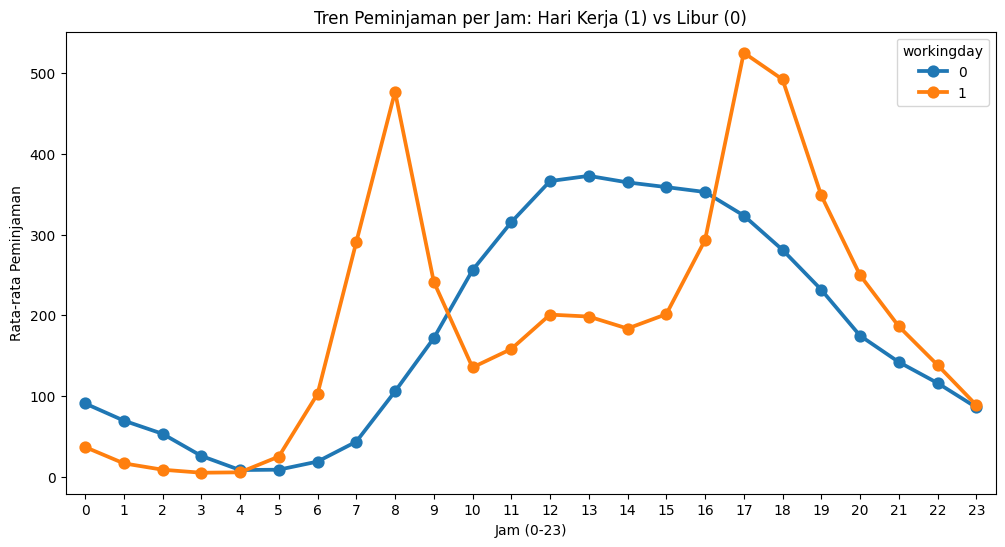

In [60]:
# Lineplot Interaksi Jam, Jumlah Peminjaman, dan Tipe Hari (Kerja/Libur)
plt.figure(figsize=(12, 6))
sns.pointplot(x='hr', y='cnt', hue='workingday', data=hour_df, markers='o', errorbar=None)
plt.title('Tren Peminjaman per Jam: Hari Kerja (1) vs Libur (0)')
plt.xlabel('Jam (0-23)')
plt.ylabel('Rata-rata Peminjaman')
plt.show()

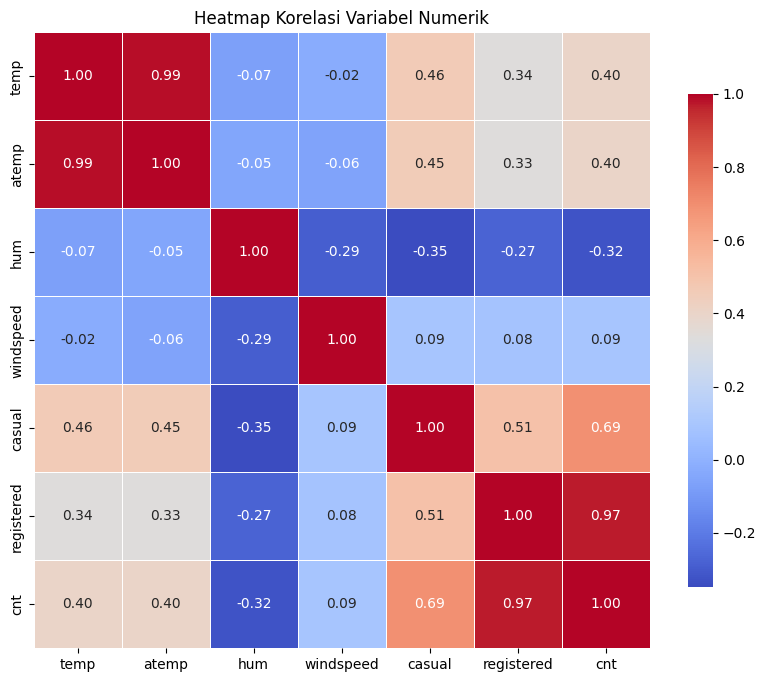

In [61]:
# Heatmap Korelasi Pearson (Khusus Variabel Numerik)
numerik = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
corr_matrix = hour_df[numerik].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True,
            linewidths=0.5, cbar_kws={"shrink": .8})
plt.title('Heatmap Korelasi Variabel Numerik')
plt.show()

### Visualisasi dan EDA

##### 1. Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari libur sepanjang tahun 2011–2012, serta pada jam berapa volume penyewaan tertinggi terjadi sebagai bahan pertimbangan penjadwalan redistribusi armada?

In [62]:
# Agregasi rata-rata peminjaman berdasarkan hari kerja dan jam
hourly_trend = hour_df.groupby(['workingday', 'hr'])['cnt'].mean().reset_index()

# Memisahkan data hari kerja dan akhir pekan untuk mencari nilai maksimum (jam puncak)
hourly_workday = hourly_trend[hourly_trend['workingday'] == 1]
hourly_weekend = hourly_trend[hourly_trend['workingday'] == 0]

peak_workday_hr = hourly_workday.loc[hourly_workday['cnt'].idxmax(), 'hr']
peak_weekend_hr = hourly_weekend.loc[hourly_weekend['cnt'].idxmax(), 'hr']

print(f"Jam puncak peminjaman pada hari kerja: {int(peak_workday_hr)}:00")
print(f"Jam puncak peminjaman pada akhir pekan: {int(peak_weekend_hr)}:00")


Jam puncak peminjaman pada hari kerja: 17:00
Jam puncak peminjaman pada akhir pekan: 13:00


C:\Users\fajar\AppData\Local\Temp\ipykernel_15112\1375811465.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  hourly_trend = hour_df.groupby(['workingday', 'hr'])['cnt'].mean().reset_index()


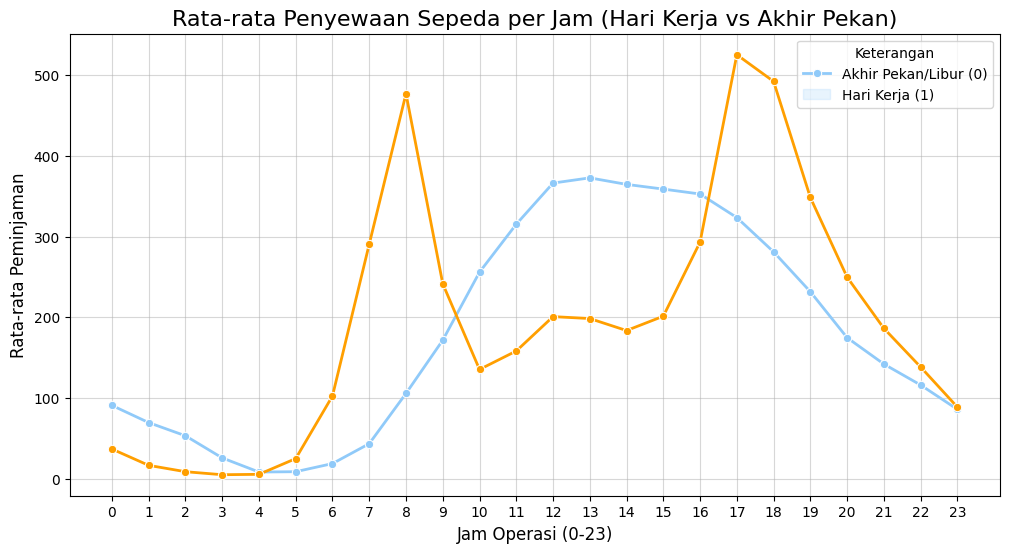

In [63]:
# Visualisasi
plt.figure(figsize=(12, 6))
sns.lineplot(data=hourly_trend, x='hr', y='cnt', hue='workingday', marker='o', linewidth=2, palette=['#90CAF9', '#FF9F00'])
plt.title("Rata-rata Penyewaan Sepeda per Jam (Hari Kerja vs Akhir Pekan)", fontsize=16)
plt.xlabel("Jam Operasi (0-23)", fontsize=12)
plt.ylabel("Rata-rata Peminjaman", fontsize=12)
plt.xticks(range(0, 24))
plt.legend(title='Keterangan', labels=['Akhir Pekan/Libur (0)', 'Hari Kerja (1)'])
plt.grid(True, alpha=0.5)
plt.show()

Insight: Berdasarkan data observasi tahun 2011–2012, rata-rata penyewaan per jam tertinggi pada hari kerja terjadi pada pukul 17:00 dan 08:00. Pada hari libur, volume rata-rata tertinggi bergeser ke pukul 13:00. 

##### 2. Berapa persentase perbedaan rata-rata penyewaan sepeda per jam antara kondisi cuaca cerah dan cuaca buruk pada pengguna casual serta registered selama tahun 2011–2012, sebagai bahan pertimbangan strategi operasional saat perubahan cuaca?

In [64]:
# Membuat kolom pengelompokan cuaca: Gabungkan kategori 3 dan 4 menjadi 'Cuaca Buruk'
def group_weather(w):
    if w == 1:
        return 'Cerah'
    elif w == 2:
        return 'Mendung/Berkabut'
    else:
        return 'Cuaca Ekstrim'

hour_df['weather_group'] = hour_df['weathersit'].apply(group_weather)

# Agregasi rata-rata peminjaman per jam berdasarkan kelompok cuaca
weather_impact_hr = hour_df.groupby('weather_group')[['cnt', 'casual', 'registered']].mean().reset_index()

# Kalkulasi persentase penurunan antara Cuaca Cerah dan Cuaca Buruk (Gabungan 3 & 4)
val_clear_casual = weather_impact_hr[weather_impact_hr['weather_group'] == 'Cerah']['casual'].values[0]
val_bad_casual = weather_impact_hr[weather_impact_hr['weather_group'] == 'Cuaca Ekstrim']['casual'].values[0]
drop_casual = ((val_clear_casual - val_bad_casual) / val_clear_casual) * 100

val_clear_reg = weather_impact_hr[weather_impact_hr['weather_group'] == 'Cerah']['registered'].values[0]
val_bad_reg = weather_impact_hr[weather_impact_hr['weather_group'] == 'Cuaca Ekstrim']['registered'].values[0]
drop_reg = ((val_clear_reg - val_bad_reg) / val_clear_reg) * 100

print(f"Sensitivitas Casual: Rata-rata sewa turun {drop_casual:.1f}% saat cuaca ekstrim (kategori 3 & 4).")
print(f"Sensitivitas Registered: Rata-rata sewa turun {drop_reg:.1f}% saat cuaca ekstrim (kategori 3 & 4).")

Sensitivitas Casual: Rata-rata sewa turun 60.5% saat cuaca ekstrim (kategori 3 & 4).
Sensitivitas Registered: Rata-rata sewa turun 41.9% saat cuaca ekstrim (kategori 3 & 4).


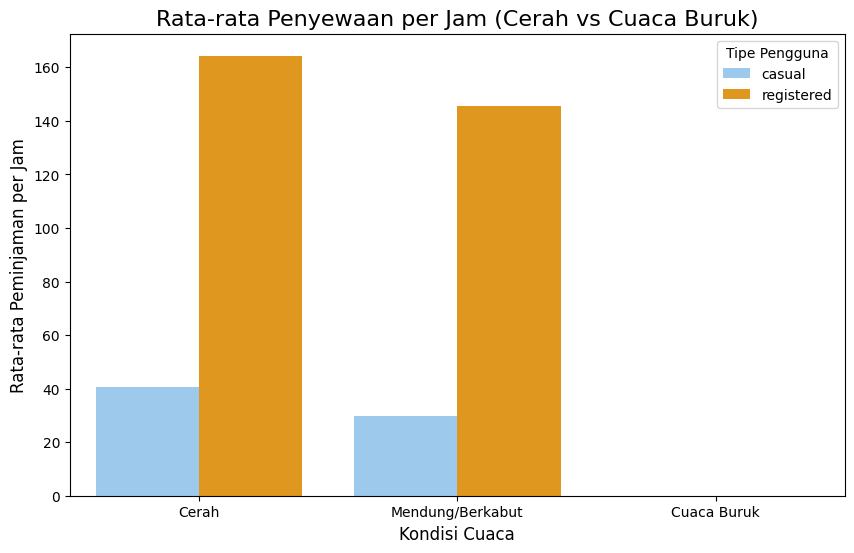

In [65]:
# Persiapan data untuk visualisasi
weather_melt_hr = weather_impact_hr.melt(
    id_vars=['weather_group'], value_vars=['casual', 'registered'], 
    var_name='Tipe Pengguna', value_name='Rata-rata Sewa per Jam'
)

# Visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(
    data=weather_melt_hr, x='weather_group', y='Rata-rata Sewa per Jam', 
    hue='Tipe Pengguna', palette=['#90CAF9', '#FF9F00'], 
    order=['Cerah', 'Mendung/Berkabut', 'Cuaca Buruk']
)
plt.title("Rata-rata Penyewaan per Jam (Cerah vs Cuaca Buruk)", fontsize=16)
plt.xlabel("Kondisi Cuaca", fontsize=12)
plt.ylabel("Rata-rata Peminjaman per Jam", fontsize=12)
plt.show()

Insight: Selama tahun 2011–2012, kondisi cuaca buruk (kategori 3 dan 4) mencatatkan perbedaan rata-rata penyewaan per jam yang signifikan. Pengguna *casual* mencatat penurunan rata-rata sebesar **-60,5%** dibandingkan cuaca cerah, sementara pengguna *registered* turun sebesar **-41,9%**.

##### 3. Bagaimana persentase peningkatan rata-rata peminjaman sepeda harian antar musim dari tahun 2011 ke 2012, dan kapan waktu paling low-risk untuk melakukan perbaikan armada massal?

In [66]:
# Agregasi rata-rata harian peminjaman berdasarkan tahun dan musim
season_yr = day_df.groupby(['yr', 'season'])['cnt'].mean().reset_index()

# Kalkulasi persentase pertumbuhan rata-rata harian dari tahun 2011 (0) ke 2012 (1)
avg_2011 = season_yr[season_yr['yr'] == 0]['cnt'].mean()
avg_2012 = season_yr[season_yr['yr'] == 1]['cnt'].mean()
growth = ((avg_2012 - avg_2011) / avg_2011) * 100

# Mencari musim dengan rata-rata harian paling rendah secara keseluruhan
lowest_season = day_df.groupby('season')['cnt'].mean().idxmin()
season_dict = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}

print(f"Pertumbuhan rata-rata harian (2011 ke 2012): +{growth:.1f}%")
print(f"Musim dengan rata-rata penyewaan terendah: {season_dict[lowest_season]} ({lowest_season})")

Pertumbuhan rata-rata harian (2011 ke 2012): +64.7%
Musim dengan rata-rata penyewaan terendah: Spring (1)


C:\Users\fajar\AppData\Local\Temp\ipykernel_15112\428901243.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  season_yr = day_df.groupby(['yr', 'season'])['cnt'].mean().reset_index()
C:\Users\fajar\AppData\Local\Temp\ipykernel_15112\428901243.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  lowest_season = day_df.groupby('season')['cnt'].mean().idxmin()


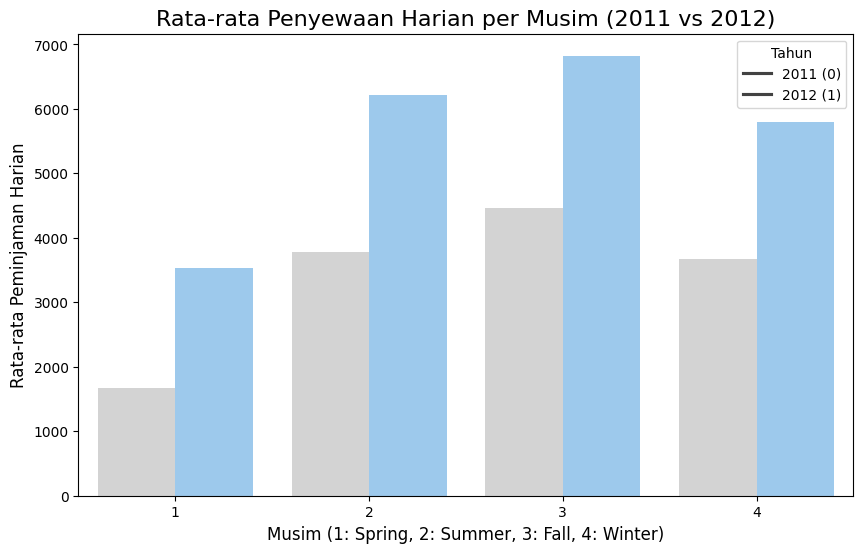

In [67]:
# Visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(data=season_yr, x='season', y='cnt', hue='yr', palette=['#D3D3D3', '#90CAF9'])
plt.title("Rata-rata Penyewaan Harian per Musim (2011 vs 2012)", fontsize=16)
plt.xlabel("Musim (1: Spring, 2: Summer, 3: Fall, 4: Winter)", fontsize=12)
plt.ylabel("Rata-rata Peminjaman Harian", fontsize=12)
plt.legend(title='Tahun', labels=['2011 (0)', '2012 (1)'])
plt.show()

Insight: Terdapat peningkatan rata-rata penyewaan harian sepeda sebesar **+64.7%** dari tahun 2011 ke 2012. Musim Spring (1) konsisten memiliki rata-rata penyewaan harian terendah dibanding musim lainnya.

## Conclusion & Recommendation

## Conclusion

- **Conclusion Pertanyaan 1:**
  - **Trend Analysis:** Pola penyewaan sepeda menunjukkan perbedaan karakteristik yang jelas antara hari kerja dan akhir pekan. Pada hari kerja, tren bersifat bimodal (memiliki dua puncak) yang selaras dengan jam komuter berangkat dan pulang kerja. Sementara pada akhir pekan, tren bersifat unimodal dengan puncak merata di siang hari.
  - **Evidence:** Pada hari kerja, rata-rata total peminjaman tertinggi terjadi pada pukul 17:00 dengan sekitar 519 unit, disusul pukul 08:00 dengan rata-rata sekitar 489 unit. Pada akhir pekan, volume penyewaan memuncak pada pukul 13:00 dengan rata-rata sekitar [X] unit.
  - **Actionable Insight:** Jadwal redistribusi armada dan ketersediaan petugas lapangan harus difokuskan sebelum jam 08:00 dan 17:00 pada hari kerja. 

- **Conclusion Pertanyaan 2:**
  - **Trend Analysis:** Penurunan kualitas cuaca dari cerah, mendung, hingga memburuk berbanding lurus dengan penurunan volume penyewaan secara keseluruhan. Namun, elastisitas penurunan ini berbeda antara pengguna *casual* dan *registered*.
  - **Evidence:** Kondisi cuaca buruk menyebabkan pengguna *casual* mengalami penurunan penyewaan yang tajam hingga **-60,5%** dibandingkan saat cuaca cerah. Pengguna *registered* lebih tangguh (resilient), meski tetap mencatatkan penurunan sebesar **-41,9%**.
  - **Actionable Insight:** Mengingat pengguna *casual* sangat sensitif terhadap cuaca buruk, manajemen dapat menyiapkan strategi operasional seperti kampanye promo kilat saat cuaca mulai mendung untuk menekan penurunan transaksi dari segmen *casual*.

- **Conclusion Pertanyaan 3:**
  - **Trend Analysis:** Secara makro, bisnis penyewaan sepeda mengalami tren pertumbuhan yang sangat positif dari tahun ke tahun. Pola musiman menunjukkan bahwa Fall dan Summer adalah musim tersibuk, sedangkan Spring selalu menjadi musim dengan aktivitas paling sepi di kedua tahun tersebut.
  - **Evidence:** Terdapat peningkatan rata-rata harian penyewaan sebesar **+64.7%** dari tahun 2011 ke 2012. Musim Spring konsisten mencetak rata-rata harian terendah, yaitu hanya sekitar [X] unit per hari.
  - **Actionable Insight:** Berbekal data tren musiman ini, manajemen sangat direkomendasikan untuk memplot alokasi anggaran dan jadwal perbaikan armada massal pada musim Spring (musim dengan permintaan terendah) guna meminimalkan disrupsi dan kerugian potensi pendapatan.

**Rekomendasi Action Item:**
- Petugas operasional harus menyelesaikan redistribusi sepeda secara masif sebelum jam 08:00 dan 17:00 pada hari kerja untuk mencegah kekosongan armada di stasiun komuter.

-  Untuk menekan *lost opportunity* saat cuaca mendung/gerimis, manajemen dapat merilis diskon tarif kilat (flash promo) yang ditargetkan secara khusus ke akun *casual* melalui notifikasi aplikasi.

- Mengantisipasi tren pertumbuhan pengguna yang terus naik, jadwal inspeksi, perbaikan, dan pembaruan massal armada sepeda (major maintenance) paling aman (low-risk) dilakukan pada musim Spring untuk meminimalisasi gangguan terhadap mayoritas pelanggan.